# ENVIRONNEMENT

In [1]:
import numpy as np

def resample_environment_around_agent(env, radius=1, change_nearby=False):
    """Resample obstacles either near the agent or far from it.

    If change_nearby=False (default), keep obstacles within a square radius of the
    agent and resample the rest. If change_nearby=True, keep obstacles outside the
    radius fixed and resample only the cells near the agent.
    """
    if radius < 0:
        raise ValueError("radius must be non-negative")

    env = env.copy()  # Work on a copy to avoid modifying the original environment
    agent_y, agent_x = map(int, env.agent_pos)

    nearby = {
        (y, x)
        for y in range(max(0, agent_y - radius), min(env.size, agent_y + radius + 1))
        for x in range(max(0, agent_x - radius), min(env.size, agent_x + radius + 1))
    }
    all_cells = {(y, x) for y in range(env.size) for x in range(env.size)}

    if change_nearby:
        # Keep distant obstacles fixed; resample only the nearby region
        distant = all_cells - nearby
        new_obstacles = {
            (y, x)
            for y in range(env.size)
            for x in range(env.size)
            if (y, x) in nearby and np.random.random() < env.p
        }
        env.obstacles = (env.obstacles & distant) | new_obstacles
    else:
        # Default behavior: keep nearby obstacles; resample the far region
        kept_obstacles = env.obstacles & nearby
        new_obstacles = {
            (y, x)
            for y in range(env.size)
            for x in range(env.size)
            if (y, x) not in nearby and np.random.random() < env.p
        }
        env.obstacles = kept_obstacles | new_obstacles

    return env.render()

class GridWorld:
    """
    Grid environment with three obstacle modes:

        "random_obstacles": each cell is blocked independently with probability p
        "deterministic_wall": fixed vertical wall and fixed door
        "random_wall": random vertical wall and random door

    Actions:
        0 = up
        1 = down
        2 = left
        3 = right
    """

    MODES = {"random_obstacles", "deterministic_wall", "random_wall", "empty"}

    def __init__(
        self,
        size=10,
        mode="deterministic_wall",
        p=0.3,
        wall_x=5,
        door_y=(7, 8),
    ):
        if mode not in self.MODES:
            raise ValueError(f"mode must be one of {sorted(self.MODES)}")
        if not 0 <= p <= 1:
            raise ValueError("p must be between 0 and 1")
        if size < 3:
            raise ValueError("size must be at least 3")

        self.size = size
        self.mode = mode
        self.p = p
        self.fixed_wall_x = wall_x
        self.fixed_door_y = tuple(door_y)

        self.action_to_delta = {
            0: (-1, 0),
            1: (1, 0),
            2: (0, -1),
            3: (0, 1),
        }

        self.reset()

    def reset(self):
        """Generate obstacles for the selected mode and sample an agent position."""
        if self.mode == "random_obstacles":
            self.wall_x = None
            self.door_y = []
            self.obstacles = {
                (y, x)
                for y in range(self.size)
                for x in range(self.size)
                if np.random.random() < self.p
            }

            # Keep at least one free cell so the agent can be placed.
            if len(self.obstacles) == self.size * self.size:
                self.obstacles.remove(
                    (np.random.randint(self.size), np.random.randint(self.size))
                )
        
        elif self.mode == "empty":
            self.wall_x = None
            self.door_y = []
            self.obstacles = set()

        else:
            if self.mode == "deterministic_wall":
                self.wall_x = self.fixed_wall_x
                self.door_y = list(self.fixed_door_y)
            else:
                self.wall_x = np.random.randint(1, self.size - 1)
                door_start = np.random.randint(0, self.size - 1)
                self.door_y = [door_start, door_start + 1]

            if not 0 <= self.wall_x < self.size:
                raise ValueError("wall_x must be within the grid")
            if any(y < 0 or y >= self.size for y in self.door_y):
                raise ValueError("door_y coordinates must be within the grid")

            self.obstacles = {
                (y, self.wall_x)
                for y in range(self.size)
                if y not in self.door_y
            }

        return self.sample_state()

    def valid_position(self, y, x):
        return (
            0 <= y < self.size
            and 0 <= x < self.size
            and (y, x) not in self.obstacles
        )

    def copy(self):
        """Return a deep copy of the current environment state."""
        new_env = GridWorld.__new__(GridWorld)
        new_env.size = self.size
        new_env.mode = self.mode
        new_env.p = self.p
        new_env.fixed_wall_x = self.fixed_wall_x
        new_env.fixed_door_y = tuple(self.fixed_door_y)
        new_env.action_to_delta = self.action_to_delta.copy()
        new_env.wall_x = self.wall_x
        new_env.door_y = list(self.door_y)
        new_env.obstacles = set(self.obstacles)
        new_env.agent_pos = np.array(self.agent_pos, dtype=np.int64, copy=True)
        return new_env

    def sample_state(self):
        """Place the agent randomly on a free cell and return the rendered image."""
        free_positions = [
            (y, x)
            for y in range(self.size)
            for x in range(self.size)
            if self.valid_position(y, x)
        ]

        if not free_positions:
            raise RuntimeError("The obstacle layout has no free cells")

        self.agent_pos = np.array(
            free_positions[np.random.randint(len(free_positions))],
            dtype=np.int64,
        )
        return self.render()

    def step(self, action):
        dy, dx = self.action_to_delta[action]
        y, x = self.agent_pos
        new_y, new_x = y + dy, x + dx

        if self.valid_position(new_y, new_x):
            self.agent_pos[:] = [new_y, new_x]

        return self.render()

    def render(self):
        """Return an RGB image of shape (size, size, 3)."""
        image = np.ones((self.size, self.size, 3), dtype=np.float32)

        for y, x in self.obstacles:
            image[y, x] = [0.0, 0.0, 0.0]

        y, x = self.agent_pos
        image[y, x] = [1.0, 0.0, 0.0]
        return image


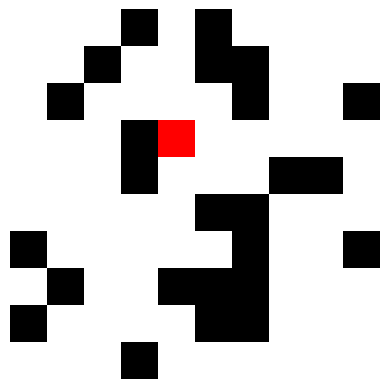

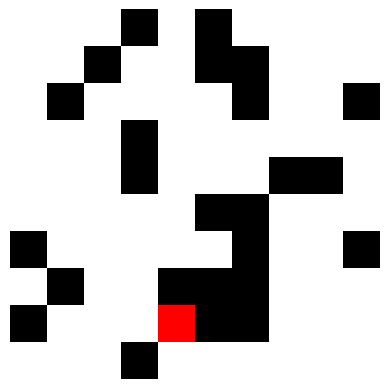

In [21]:
import matplotlib.pyplot as plt

env = GridWorld(mode = "random_obstacles")
x = env.reset()

plt.imshow(x)
plt.axis("off")
plt.show()

x = env.sample_state()

plt.imshow(x)
plt.axis("off")
plt.show()

# MODELS

In [209]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import copy


def reparameterize(mean, variance):
    return mean + torch.randn_like(mean) * torch.sqrt(variance)


def gaussian_kl_to_standard_normal(mean, variance):
    kl_per_sample = 0.5 * (
        mean.square() + variance - 1.0 - torch.log(variance)
    ).sum(dim=-1)
    return kl_per_sample.mean()


class Encoder(nn.Module):
    """Image encoder with a diagonal Gaussian latent distribution."""

    def __init__(self, latent_dim=64):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Flatten(),
        )
        self.mean_head = nn.Linear(64 * 10 * 10, latent_dim)
        self.log_variance_head = nn.Linear(64 * 10 * 10, latent_dim)

    def distribution(self, x):
        features = self.network(x)
        mean = self.mean_head(features)
        log_variance = self.log_variance_head(features).clamp(-10.0, 10.0)
        variance = log_variance.exp()
        return mean, variance

    def forward(self, x, sample=False):
        mean, variance = self.distribution(x)
        if sample:
            return reparameterize(mean, variance)
        return mean


class GaussianLatentEncoder(nn.Module):
    """Map a latent vector to a diagonal Gaussian distribution."""

    def __init__(self, in_dim, latent_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
        )
        self.mean_head = nn.Linear(128, latent_dim)
        self.log_variance_head = nn.Linear(128, latent_dim)

    def distribution(self, x):
        features = self.network(x)
        mean = self.mean_head(features)
        log_variance = self.log_variance_head(features).clamp(-10.0, 10.0)
        variance = log_variance.exp()
        return mean, variance

    def forward(self, x, sample=False):
        mean, variance = self.distribution(x)
        if sample:
            return reparameterize(mean, variance)
        return mean


class Decoder(nn.Module):
    """latent representation -> Action"""

    def __init__(self, dim_1=64, dim_2=64):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(dim_1 + dim_2, 4),
        )

    def forward(self, x, x_next):
        x = torch.cat([x, x_next], dim=-1)
        return self.network(x)


class Predictor(nn.Module):
    """(latent state, action) -> predicted next latent state"""

    def __init__(self, in_dim=64, out_dim=64, num_actions=4, context=False):
        super().__init__()
        self.context = context

        if context:
            self.network = nn.Sequential(
                nn.Linear(in_dim, 128),
                nn.ReLU(),
                nn.Linear(128, 128),
                nn.ReLU(),
                nn.Linear(128, out_dim)
            )
        else:
            self.action_embedding = nn.Embedding(num_actions, in_dim)
            self.network = nn.Sequential(
                nn.Linear(in_dim * 2, 128),
                nn.ReLU(),
                nn.Linear(128, 128),
                nn.ReLU(),
                nn.Linear(128, out_dim)
            )

    def forward(self, z, action=None):
        if self.context:
            return self.network(z)

        action_embedding = self.action_embedding(action)
        x = torch.cat([z, action_embedding], dim=-1)
        return self.network(x)


class LinearPredictor(nn.Module):
    """(latent state x, action u) -> predicted next latent state."""

    def __init__(self, in_dim=64, out_dim=64, num_actions=4, context=False):
        super().__init__()
        self.in_dim = in_dim
        self.out_dim = out_dim
        self.context = context

        if context:
            self.network = nn.Sequential(
                nn.Linear(in_dim, out_dim),
            )
        else:
            self.action_embedding = nn.Embedding(num_actions, in_dim)
            self.network = nn.Sequential(
                nn.Linear(in_dim, 128),
                nn.ReLU(),
                nn.Linear(128, 128),
                nn.ReLU(),
                nn.Linear(128, out_dim * in_dim)
            )

    def forward(self, x, action=None, context = None, residual_action=False):
        if self.context:
            return self.network(x)

        if residual_action:
            action_embedding = self.action_embedding(action)
            batch_size = x.shape[0]
            matrix = self.network(x).view(batch_size, self.out_dim, self.in_dim)
            delta = torch.bmm(matrix, action_embedding.unsqueeze(-1)).squeeze(-1)
            return x + delta

        batch_size = x.shape[0]
        matrix = self.network(
            self.action_embedding(action)
        ).view(batch_size, self.out_dim, self.in_dim)
        return torch.bmm(matrix, x.unsqueeze(-1)).squeeze(-1)


class JEPA(nn.Module):
    def __init__(self, latent_dim=64, linear=False, sep=False):
        super().__init__()

        local_dim = 32 if sep else 0
        agent_dim = 8 if sep else 0
        context_dim = latent_dim - agent_dim

        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim, latent_dim) if not sep else Decoder(local_dim, agent_dim)
        if linear:
            self.predictor = LinearPredictor(latent_dim, latent_dim) if not sep else LinearPredictor(local_dim, agent_dim)
            self.predictor_context = LinearPredictor(latent_dim, context_dim, context=True)
            self.adv_predictor = LinearPredictor(local_dim, agent_dim, context=True)
        else:
            self.predictor = Predictor(latent_dim, latent_dim) if not sep else Predictor(local_dim, agent_dim)
            self.predictor_context = Predictor(latent_dim, context_dim, context=True)
            self.adv_predictor = Predictor(local_dim, agent_dim, context=True)

        self.encoder_local = GaussianLatentEncoder(latent_dim, local_dim)
        self.target_encoder = copy.deepcopy(self.encoder)
        self.linear = linear

    def encode(self, x):
        return self.encoder(x)

    def predict(self, z, action):
        return self.predictor(z, action)

    def forward(self, x_t, action):
        z_t = self.encode(x_t)
        z_next_pred = self.predict(z_t, action)
        return z_next_pred

# TRAINING

In [4]:
def generate_dataset(num_transitions=50000, mode="deterministic_wall"):

    env = GridWorld(mode=mode)

    states = []
    actions = []
    next_states = []
    goal_states = []

    for _ in range(num_transitions):

        # -------------------------
        # Sample a new environment
        # -------------------------
        env.reset()

        # -------------------------
        # Sample valid current state
        # -------------------------
        state = env.sample_state()

        # -------------------------
        # Take action from S_t
        # -------------------------
        action = np.random.randint(0, 4)

        next_state = env.step(action)

        # -------------------------
        # Sample valid goal
        # -------------------------
        goal_state = env.sample_state()
        

        # -------------------------
        # Store transition
        # -------------------------
        states.append(state)
        actions.append(action)
        next_states.append(next_state)
        goal_states.append(goal_state)

    return (
        np.array(states),
        np.array(actions),
        np.array(next_states),
        np.array(goal_states)
    )

In [5]:
import numpy as np


def generate_trajectory_dataset(
    num_trajectories=5000,
    trajectory_length=20,
    mode="deterministic_wall"
):
    if trajectory_length < 2:
        raise ValueError("trajectory_length must be at least 2")

    env = GridWorld(mode=mode)

    all_states = []
    all_actions = []
    all_next_states = []
    all_goal_states = []

    for _ in range(num_trajectories):
        # Reset each trajectory so modes that randomize the map can resample it.
        env.reset()

        while True:
            agent_pos = np.random.randint(0, env.size, size=2)
            if env.valid_position(*agent_pos):
                break
        env.agent_pos = agent_pos.copy()

        while True:
            goal_pos = np.random.randint(0, env.size, size=2)
            if (
                env.valid_position(*goal_pos)
                and not np.array_equal(goal_pos, agent_pos)
            ):
                break

        original_pos = env.agent_pos.copy()
        env.agent_pos = goal_pos.copy()
        goal_state = env.render().copy()
        env.agent_pos = original_pos

        trajectory_states = []
        trajectory_actions = []
        trajectory_next_states = []

        for _ in range(trajectory_length - 1):
            trajectory_states.append(env.render().copy())

            action = np.random.randint(0, 4)
            next_state = env.step(action)

            trajectory_actions.append(action)
            trajectory_next_states.append(next_state.copy())

        trajectory_states.append(env.render().copy())

        all_states.append(np.stack(trajectory_states))
        all_actions.append(np.asarray(trajectory_actions, dtype=np.int64))
        all_next_states.append(np.stack(trajectory_next_states))
        all_goal_states.append(goal_state)

    return (
        np.stack(all_states),
        np.stack(all_actions),
        np.stack(all_next_states),
        np.stack(all_goal_states)
    )

In [6]:
import torch
from torch.utils.data import Dataset, DataLoader


class TransitionDataset(Dataset):

    def __init__(
        self,
        states,
        actions,
        next_states,
        goal_states
    ):

        self.states = torch.tensor(
            states,
            dtype=torch.float32
        )

        self.actions = torch.tensor(
            actions,
            dtype=torch.long
        )

        self.next_states = torch.tensor(
            next_states,
            dtype=torch.float32
        )

        self.goal_states = torch.tensor(
            goal_states,
            dtype=torch.float32
        )

        # -----------------------------------------------------
        # Detect dataset type
        # -----------------------------------------------------

        if self.states.ndim == 4:
            # -----------------------------------------------
            # Transition dataset
            #
            # states: (N, H, W, C)
            # -----------------------------------------------

            self.is_trajectory = False

            self.states = self.states.permute(
                0, 3, 1, 2
            )

            self.next_states = self.next_states.permute(
                0, 3, 1, 2
            )

            self.goal_states = self.goal_states.permute(
                0, 3, 1, 2
            )

        elif self.states.ndim == 5:
            # -----------------------------------------------
            # Trajectory dataset
            #
            # states: (N, T, H, W, C)
            # -----------------------------------------------

            self.is_trajectory = True

            N, T, H, W, C = self.states.shape

            # (N, T, H, W, C)
            # -> (N, T, C, H, W)
            self.states = self.states.permute(
                0, 1, 4, 2, 3
            )

            # next_states:
            # (N, T-1, H, W, C)
            # -> (N, T-1, C, H, W)
            self.next_states = self.next_states.permute(
                0, 1, 4, 2, 3
            )

            # goal_states:
            # (N, H, W, C)
            # -> (N, C, H, W)
            self.goal_states = self.goal_states.permute(
                0, 3, 1, 2
            )

            self.num_trajectories = N
            self.trajectory_length = T

        else:
            raise ValueError(
                "states must have shape "
                "(N,H,W,C) or (N,T,H,W,C)"
            )

    def __len__(self):

        if self.is_trajectory:
            # Each timestep except the final state
            # corresponds to one transition.
            return (
                self.num_trajectories
                * (self.trajectory_length - 1)
            )

        else:
            return len(self.actions)

    def __getitem__(self, idx):

        if not self.is_trajectory:

            # ---------------------------------------------
            # Transition dataset
            # ---------------------------------------------

            return (
                self.states[idx],
                self.actions[idx],
                self.next_states[idx],
                self.goal_states[idx]
            )

        else:

            # ---------------------------------------------
            # Trajectory dataset
            # ---------------------------------------------

            # Convert flat index into:
            #
            # trajectory index i
            # timestep t
            #
            T_minus_1 = self.trajectory_length - 1

            trajectory_idx = idx // T_minus_1
            timestep = idx % T_minus_1

            state = self.states[
                trajectory_idx,
                timestep
            ]

            action = self.actions[
                trajectory_idx,
                timestep
            ]

            next_state = self.next_states[
                trajectory_idx,
                timestep
            ]

            # Same goal for the whole trajectory
            goal_state = self.goal_states[
                trajectory_idx
            ]

            return (
                state,
                action,
                next_state,
                goal_state
            )

In [7]:
import torch


def sigreg_loss(z, num_projections=64, num_knots=17, t_max=3.0):
    """
    Sketched Isotropic Gaussian Regularization (SIGReg).

    z: (B, D)
    """

    B, D = z.shape

    # Random normalized projections
    projections = torch.randn(
        D,
        num_projections,
        device=z.device,
        dtype=z.dtype
    )

    projections = projections / (
        projections.norm(dim=0, keepdim=True) + 1e-8
    )

    # Project latent representations
    # (B, D) -> (B, num_projections)
    z_proj = z @ projections

    # Evaluation points
    t = torch.linspace(
        0.0,
        t_max,
        num_knots,
        device=z.device,
        dtype=z.dtype
    )

    # Gaussian characteristic function
    target_cf = torch.exp(-0.5 * 1 * t.square())
    # Empirical characteristic function
    angles = z_proj.unsqueeze(-1) * t

    empirical_cf = torch.exp(
        1j * angles
    ).mean(dim=0)

    # Squared difference from N(0,1)
    error = (
        empirical_cf
        - target_cf.unsqueeze(0)
    ).abs().square()

    # Trapezoidal integration
    dt = t[1] - t[0]

    weights = torch.ones_like(t)
    weights[0] *= 0.5
    weights[-1] *= 0.5

    loss = (
        error
        * weights.unsqueeze(0)
    ).sum(dim=-1) * dt

    return loss.mean()

In [308]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


def train_jepa(
    model,
    train_loader,
    num_epochs=30,
    lr=1e-3,
    tau=0.99,
    beta_kl=1e-3,
    agent_dim = 8,
    device="cuda",
    deterministic=True,
    sep = True,
):
    model = model.to(device)

    optimizer_encoder = torch.optim.AdamW(
        list(model.encoder.parameters()) + list(model.encoder_local.parameters()),
        lr=lr,
        weight_decay=1e-4
    )
    optimizer_predictor = torch.optim.AdamW(
        list(model.predictor.parameters()) + list(model.predictor_context.parameters()) +
        list(model.decoder.parameters()),
        lr=lr,
        weight_decay=1e-4
    )
    optimizer_adv_predictor = torch.optim.AdamW(
        list(model.adv_predictor.parameters()),
        lr=lr * 0.1,
        weight_decay=1e-4
    )

    epoch_losses = []

    for epoch in range(num_epochs):
        model.train()
        total_loss = 0.0

        for x_t, action, x_next, x_goal in train_loader:
            x_t = x_t.to(device).reshape(-1, *x_t.shape[-3:])
            x_goal = x_goal.to(device)
            action = action.to(device)
            x_next = x_next.to(device).reshape(-1, *x_next.shape[-3:])

            # Apply the information bottleneck only to the first agent_dim image-latent dimensions.
            mu_t, var_t = model.encoder.distribution(x_t)
            mu_next, var_next = model.encoder.distribution(x_next)
            mu_goal, var_goal = model.encoder.distribution(x_goal)
            if deterministic:
                z_t, z_next, z_goal = mu_t, mu_next, mu_goal
            else:
                z_t = torch.cat((
                    reparameterize(mu_t[:, :agent_dim], var_t[:, :agent_dim]),
                    mu_t[:, agent_dim:]
                ), dim=-1)
                z_next = torch.cat((
                    reparameterize(mu_next[:, :agent_dim], var_next[:, :agent_dim]),
                    mu_next[:, agent_dim:]
                ), dim=-1)
                z_goal = torch.cat((
                    reparameterize(mu_goal[:, :agent_dim], var_goal[:, :agent_dim]),
                    mu_goal[:, agent_dim:]
                ), dim=-1)

            if sep:
                z_context_pred = model.predictor_context(z_t)
                mu_local, var_local = model.encoder_local.distribution(z_t)
                z_local = mu_local if deterministic else reparameterize(mu_local, var_local)
                z_local_pred = model.predictor(z_local, action)
                z_local_pred_adv = model.adv_predictor(z_local.detach())
                z_next_pred = torch.cat([z_local_pred, z_context_pred], dim=-1)
            else:
                z_next_pred = model.predictor(z_t, action)

            with torch.no_grad():
                z_t_target = model.target_encoder(x_t)
                z_next_target = model.target_encoder(x_next)
                z_goal_target = model.target_encoder(x_goal)

            same_state = torch.all(
                x_t == x_goal,
                dim=tuple(range(1, x_t.ndim))
            )
            cost = (~same_state).float()
            Vloss = -cost - 0.99 * torch.norm(z_next_target - z_goal_target, dim=-1) + torch.norm(z_t - z_goal, dim=-1)
            Vloss = torch.where(
                Vloss < 0,
                0.3 * Vloss**2,
                0.7 * Vloss**2
            ).mean()

            normalized_z = z_t / torch.sqrt(torch.sum(z_t**2, dim=0, keepdim=True) + 1e-8)
            covariance = normalized_z.T @ normalized_z / normalized_z.shape[0]
            sign, logdet = torch.linalg.slogdet(
                covariance + 1e-8 * torch.eye(covariance.shape[0], device=covariance.device)
            )

            if sep:
                action_rec = model.decoder(z_local, z_next[:, :agent_dim])
            else:
                action_rec = model.decoder(z_t, z_next)
            pred_error = torch.norm(z_next_pred - z_next, dim=-1)
            C = torch.relu(torch.norm(z_next_pred - z_t, dim=-1) - cost)
            reg = torch.abs(100 - torch.norm(z_t - z_goal, dim=-1, p=1))
            action_rec_loss = nn.CrossEntropyLoss()(action_rec, action.long())
            sigreg = sigreg_loss(z_t)
            invert_loss = -logdet

            if sep:
                p = z_local**2 / (torch.norm(z_local, dim=-1, p=2).unsqueeze(-1)**2 + 1e-8)
                entropie = -(p * torch.log(p + 1e-8)).sum(dim=-1)
                sparsity = torch.norm(z_local, dim=-1, p=1)

                p2 = z_t[:, :agent_dim]**2 / (torch.norm(z_t[:, :agent_dim], dim=-1, p=2).unsqueeze(-1)**2 + 1e-8)
                entropie2 = -(p2 * torch.log(p2 + 1e-8)).sum(dim=-1)
                sparsity2 = torch.norm(z_t[:, :agent_dim], dim=-1, p=1)

                loss_adv_neg = torch.norm(
                    F.normalize(z_local_pred_adv.detach(), dim=-1)
                    - F.normalize(z_next[:, :agent_dim], dim=-1),
                    dim=-1
                )

                kl_local = gaussian_kl_to_standard_normal(mu_local, var_local)

                kl_image = gaussian_kl_to_standard_normal(mu_t[:, :agent_dim], var_t[:, :agent_dim])
                kl_image_next = gaussian_kl_to_standard_normal(
                    mu_next[:, :agent_dim], var_next[:, :agent_dim]
                )
                kl_loss = kl_image + kl_local + kl_image_next

                jepa_loss = pred_error.square() + action_rec_loss #+ beta_kl * kl_loss
            
            else:
                jepa_loss = pred_error.square() + action_rec_loss 
            
            loss = jepa_loss.mean() 

            optimizer_encoder.zero_grad()
            optimizer_predictor.zero_grad()
            loss.backward()
            optimizer_predictor.step()
            optimizer_encoder.step()

            #loss_adv_pos = torch.norm(
            #    F.normalize(z_local_pred_adv, dim=-1)
            #    - F.normalize(z_next[:, :16].detach(), dim=-1),
            #    dim=-1
            #)
            #loss_adv = loss_adv_pos.mean()

            #optimizer_adv_predictor.zero_grad()
            #loss_adv.backward()
            #optimizer_adv_predictor.step()

            with torch.no_grad():
                for target_param, online_param in zip(
                    model.target_encoder.parameters(),
                    model.encoder.parameters()
                ):
                    target_param.data.mul_(1.0 - tau)
                    target_param.data.add_(tau * online_param.data)

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        epoch_losses.append(avg_loss)

        if sep:
            print(
                f"Epoch {epoch + 1:03d} | "
                f"Loss: {avg_loss:.6f} | "
                f"KL: {kl_loss.item():.6f}"
            )
        else:
            print(
                f"Epoch {epoch + 1:03d} | "
                f"Loss: {avg_loss:.6f}"
            )
        with torch.no_grad():
            print(
                "mean:", z_t.mean().item(),
                "std:", z_t.std(dim=0).mean().item(),
                "norm:", z_t.norm(dim=-1).mean().item(),
                "pred error:", pred_error.mean().item(),
                "C:", torch.norm(z_next_pred - z_t, dim=-1).mean().item(),
                "actions:", action_rec_loss.mean().item(),
                "sigreg:", sigreg.mean().item(),
            )

    plt.figure(figsize=(8, 4))
    plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Average training loss")
    plt.title("Training loss by epoch")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return model

In [309]:
import torch
import torch.nn.functional as F


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Generate data
states, actions, next_states, goals = generate_trajectory_dataset(
    50000//20, mode = "random_obstacles"
)

dataset = TransitionDataset(
    states,
    actions,
    next_states,
    goals
)
print(dataset[0][0].shape)

train_loader = DataLoader(
    dataset,
    batch_size=256,
    shuffle=True
)

torch.Size([3, 10, 10])


In [420]:
# Model
sep = True

model = JEPA(
    latent_dim=128, linear = True, sep = sep
)

device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
model = train_jepa(
    model,
    train_loader,
    num_epochs=150,
    lr=1e-3,
    tau=1.0,
    device=device,
    beta_kl=1e-3,
    sep = sep
)

Epoch 001 | Loss: 35.241292 | KL: 0.187040
mean: -0.0005933225038461387 std: 0.0 norm: 0.4349409341812134 pred error: 0.01690875180065632 C: 0.01690875180065632 actions: 1.3867326974868774 sigreg: 1.3887505531311035


# VISUALIZATION

In [408]:
mode = "deterministic_wall" # "random_obstacles" ; "random_wall" ; "deterministic_wall"
env = GridWorld(mode = mode)

view_all = 1 # -1 for context, 0 for local, 1 for both
dim_local = 16

In [409]:
import numpy as np
import torch
import matplotlib.pyplot as plt


@torch.no_grad()
def latent_distance_map(
    model,
    target_pos,
    mode,
    device="cuda",
):
    """
    Compute the latent-space distance between a target state
    and every possible agent position.

    target_pos: (y, x)
    """

    model.eval()
    device = torch.device(device)

    env = GridWorld(mode = mode)

    # ---------------------------------------------------------
    # 1. Encode the target state
    # ---------------------------------------------------------

    env.agent_pos = np.array(target_pos, dtype=np.int64)

    target_image = env.render()


    target_image = torch.tensor(
        target_image,
        dtype=torch.float32
    )

    # H,W,C -> 1,C,H,W
    target_image = target_image.permute(
        2, 0, 1
    ).unsqueeze(0).to(device)

    # Encode target
    target_z = model.encoder(
        target_image
    )

    #z = model.predictor(target_z, torch.tensor([2]).to(device))
    #z = model.predictor(z, torch.tensor([2]).to(device))
    #z = model.predictor(z, torch.tensor([2]).to(device))
    #z = model.predictor(z, torch.tensor([2]).to(device))
    #z = model.predictor(z, torch.tensor([2]).to(device))
    #z = model.predictor(z, torch.tensor([2]).to(device))
    #z = model.predictor(z, torch.tensor([2]).to(device))

    #print(torch.norm(model.predictor(target_z, torch.tensor([0]).to(device)) - target_z, dim=-1))
    #target_z = z


    # ---------------------------------------------------------
    # 2. Compute distance for every position
    # ---------------------------------------------------------

    distance_map = np.full(
        (env.size, env.size),
        np.nan
    )

    for y in range(env.size):

        for x in range(env.size):

            # Skip wall positions
            if not env.valid_position(y, x):
                continue

            # Put agent at this position
            env.agent_pos = np.array(
                [y, x],
                dtype=np.int64
            )

            image = env.render()

            image = torch.tensor(
                image,
                dtype=torch.float32
            )

            image = image.permute(
                2, 0, 1
            ).unsqueeze(0).to(device)

            # Encode
            z = model.encoder(image)

            if view_all == 1:
                d = torch.norm(
                    (z - target_z),
                    dim=-1, p=2
                )
            elif view_all == 0:
                d = torch.norm(
                    (z[:,:dim_local] - target_z[:,:dim_local]),
                    dim=-1, p=2
                )
            elif view_all == -1:
                d = torch.norm(
                    (z[:,dim_local:] - target_z[:,dim_local:]),
                    dim=-1, p=2
                )
            distance_map[y, x] = d.item()
    
    env.agent_pos = np.array(target_pos, dtype=np.int64)

    return distance_map, env

In [410]:
# ---------------------------------------------------------
# Choose target state
# ---------------------------------------------------------

target_pos = (0,6)

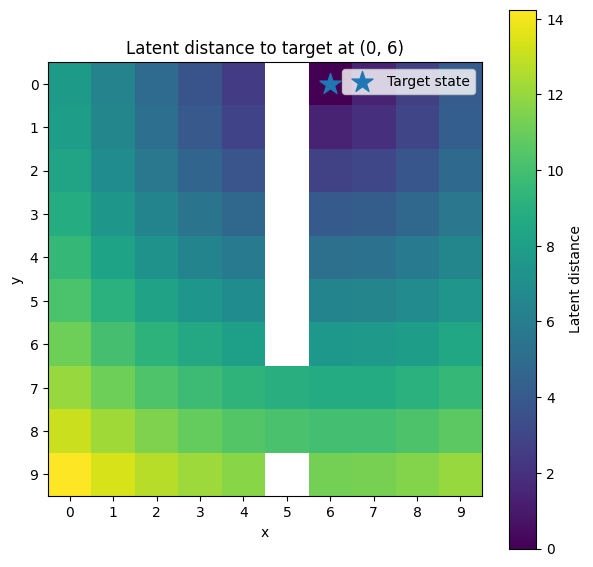

In [411]:
# ---------------------------------------------------------
# Compute latent distances
# ---------------------------------------------------------

distance_map, env = latent_distance_map(
    model,
    target_pos=target_pos,
    mode = mode,
    device=device,)


# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.imshow(
    distance_map,
    origin="upper"
)

plt.colorbar(
    label="Latent distance"
)

# Mark target
plt.scatter(
    target_pos[1],
    target_pos[0],
    marker="*",
    s=250,
    label="Target state"
)

plt.xticks(range(10))
plt.yticks(range(10))

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    f"Latent distance to target at {target_pos}"
)

plt.legend()

plt.show()

In [412]:
radius = 2

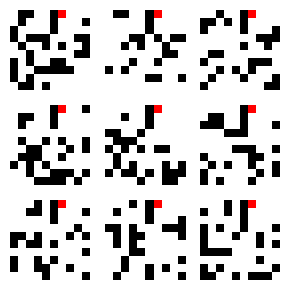

Representations shape: (1024, 128)
Mean local variance: 0.016373813152313232
Mean context variance: 4.2134051909670234e-05
Mean prediction variance: 0.0010455050505697727


In [413]:
n_samples = 1024

images = np.stack([
    resample_environment_around_agent(env, radius=radius)
    for _ in range(n_samples)
])
# Display the first 64 sampled environments as an 8x8 grid
fig, axes = plt.subplots(3, 3, figsize=(3, 3))
for ax, img in zip(axes.flat, images[:9]):
    ax.imshow(img)
    ax.set_axis_off()
fig.tight_layout()
plt.show()

images = torch.tensor(
    images,
    dtype=torch.float32,
    device=device
).permute(0, 3, 1, 2)

model.eval()
with torch.no_grad():
    representations = model.encoder(images)
    if sep:
        representations_local = model.encoder_local(representations)
        prediction_local = model.predictor(representations_local, torch.tensor([1]*1024, dtype=torch.long, device=device))
        representations_context = model.predictor_context(representations)
    else:
        representations_local = representations
        representations_context = representations
        prediction_local = model.predictor(representations, torch.tensor([1]*1024, dtype=torch.long, device=device))

# Variance across samples, for each latent dimension
variance_per_dim_local = representations_local.var(dim=0, unbiased=False)
mean_variance_local = variance_per_dim_local.mean().item()

variance_per_dim_context = representations_context.var(dim=0, unbiased=False)
mean_variance_context = variance_per_dim_context.mean().item()

variance_per_dim_prediction = prediction_local.var(dim=0, unbiased=False)
mean_variance_prediction = variance_per_dim_prediction.mean().item()

print("Representations shape:", tuple(representations.shape))
print("Mean local variance:", mean_variance_local)
print("Mean context variance:", mean_variance_context)
print("Mean prediction variance:", mean_variance_prediction)

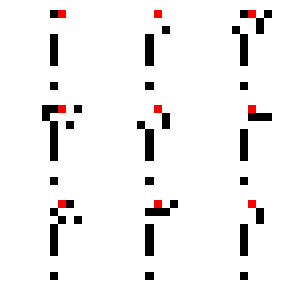

Representations shape: (1024, 128)
Mean local variance: 0.4090957045555115
Mean context variance: 5.945096563664265e-05
Mean prediction variance: 0.04431618005037308


In [414]:
n_samples = 1024

images = np.stack([
    resample_environment_around_agent(env, radius=radius, change_nearby=True)
    for _ in range(n_samples)
])
# Display the first 64 sampled environments as an 8x8 grid
fig, axes = plt.subplots(3, 3, figsize=(3, 3))
for ax, img in zip(axes.flat, images[:9]):
    ax.imshow(img)
    ax.set_axis_off()
fig.tight_layout()
plt.show()

images = torch.tensor(
    images,
    dtype=torch.float32,
    device=device
).permute(0, 3, 1, 2)

model.eval()
with torch.no_grad():
    representations = model.encoder(images)
    if sep:
        representations_local = model.encoder_local(representations)
        prediction_local = model.predictor(representations_local, torch.tensor([1]*1024, dtype=torch.long, device=device))
        representations_context = model.predictor_context(representations)
    else:
        representations_local = representations
        representations_context = representations
        prediction_local = model.predictor(representations, torch.tensor([1]*1024, dtype=torch.long, device=device))

# Variance across samples, for each latent dimension
variance_per_dim_local = representations_local.var(dim=0, unbiased=False)
mean_variance_local_3 = variance_per_dim_local.mean().item()

variance_per_dim_context = representations_context.var(dim=0, unbiased=False)
mean_variance_context_3 = variance_per_dim_context.mean().item()

variance_per_dim_prediction = prediction_local.var(dim=0, unbiased=False)
mean_variance_prediction_3 = variance_per_dim_prediction.mean().item()

print("Representations shape:", tuple(representations.shape))
print("Mean local variance:", mean_variance_local_3)
print("Mean context variance:", mean_variance_context_3)
print("Mean prediction variance:", mean_variance_prediction_3)

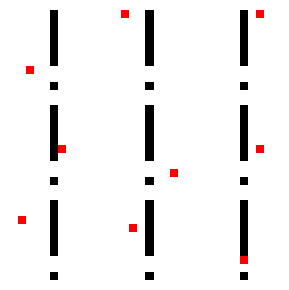

Representations shape: (1024, 128)
Mean local variance: 17.024059295654297
Mean context variance: 0.000265737297013402
Mean prediction variance: 3.288550853729248


In [415]:
n_samples = 1024

images = np.stack([
    env.copy().reset()
    for _ in range(n_samples)
])
# Display the first 64 sampled environments as an 8x8 grid
fig, axes = plt.subplots(3, 3, figsize=(3, 3))
for ax, img in zip(axes.flat, images[:9]):
    ax.imshow(img)
    ax.set_axis_off()
fig.tight_layout()
plt.show()

images = torch.tensor(
    images,
    dtype=torch.float32,
    device=device
).permute(0, 3, 1, 2)

model.eval()
with torch.no_grad():
    representations = model.encoder(images)
    if sep:
        representations_local = model.encoder_local(representations)
        prediction_local = model.predictor(representations_local, torch.tensor([1]*1024, dtype=torch.long, device=device))
        representations_context = model.predictor_context(representations)
    else:
        representations_local = representations
        representations_context = representations
        prediction_local = model.predictor(representations, torch.tensor([1]*1024, dtype=torch.long, device=device))

# Variance across samples, for each latent dimension
variance_per_dim_local = representations_local.var(dim=0, unbiased=False)
mean_variance_local_2 = variance_per_dim_local.mean().item()

variance_per_dim_context = representations_context.var(dim=0, unbiased=False)
mean_variance_context_2 = variance_per_dim_context.mean().item()

variance_per_dim_prediction = prediction_local.var(dim=0, unbiased=False)
mean_variance_prediction_2 = variance_per_dim_prediction.mean().item()

print("Representations shape:", tuple(representations.shape))
print("Mean local variance:", mean_variance_local_2)
print("Mean context variance:", mean_variance_context_2)
print("Mean prediction variance:", mean_variance_prediction_2)


In [416]:
print("FAR MODIFICATION")
print("Relative local variance:", mean_variance_local/mean_variance_local_2)
print("Relative context variance:", mean_variance_context/mean_variance_context_2)
print("Relative prediction variance:", mean_variance_prediction/mean_variance_prediction_2)

print("NEAR MODIFICATION")
print("Relative local variance:", mean_variance_local_3/mean_variance_local_2)
print("Relative context variance:", mean_variance_context_3/mean_variance_context_2)
print("Relative prediction variance:", mean_variance_prediction_3/mean_variance_prediction_2)

FAR MODIFICATION
Relative local variance: 0.0009618042834527102
Relative context variance: 0.15855528141217332
Relative prediction variance: 0.0003179227255628904
NEAR MODIFICATION
Relative local variance: 0.024030444058658833
Relative context variance: 0.223720818661162
Relative prediction variance: 0.013475899270378655


In [417]:
n_transitions = 1000
eval_batch_size = 128

# Sample real one-step transitions from the current environment map.
eval_env = env.copy()
free_positions = [
    (y, x) for y in range(eval_env.size) for x in range(eval_env.size)
    if eval_env.valid_position(y, x)
]

states_eval, next_states_eval, actions_eval = [], [], []
for _ in range(n_transitions):
    position = free_positions[np.random.randint(len(free_positions))]
    action = np.random.randint(4)

    eval_env.agent_pos = np.array(position, dtype=np.int64)
    states_eval.append(eval_env.render().copy())
    actions_eval.append(action)
    next_states_eval.append(eval_env.step(action).copy())

model.eval()
model_device = next(model.parameters()).device
dispersion, prediction_errors = [], []

with torch.no_grad():
    for start in range(0, n_transitions, eval_batch_size):
        end = min(start + eval_batch_size, n_transitions)

        state_batch = torch.as_tensor(
            np.stack(states_eval[start:end]), dtype=torch.float32, device=model_device
        ).permute(0, 3, 1, 2)
        next_batch = torch.as_tensor(
            np.stack(next_states_eval[start:end]), dtype=torch.float32, device=model_device
        ).permute(0, 3, 1, 2)

        z_state = model.encoder(state_batch)
        z_next = model.encoder(next_batch)

        batch_size = z_state.shape[0]
        all_actions = torch.arange(4, device=model_device).repeat(batch_size)
        repeated_state = z_state.repeat_interleave(4, dim=0)

        if sep:
            predictor_input = model.encoder_local(z_state)
            repeated_input = predictor_input.repeat_interleave(4, dim=0)
            predictions = model.predictor(repeated_input, all_actions).reshape(batch_size, 4, -1)
            prediction_context = model.predictor_context(z_state).unsqueeze(1).repeat(1, 4, 1)
            predictions = torch.cat([predictions, prediction_context], dim=-1)
            target = z_next
        else:
            predictions = model.predictor(repeated_state, all_actions).reshape(batch_size, 4, -1)
            target = z_next

        # Mean per-dimension standard deviation across the four action predictions.
        # predictions shape: [batch_size, 4, latent_dim]

        centroid = predictions.mean(dim=1, keepdim=True)

        distances = torch.norm(
            predictions - centroid,
            p=2,
            dim=-1
        )  # [batch_size, 4]

        dispersion_per_state = distances.mean(dim=1)

        dispersion.append(dispersion_per_state)


        chosen_actions = torch.as_tensor(
            actions_eval[start:end], dtype=torch.long, device=model_device
        )
        chosen_predictions = predictions[
            torch.arange(batch_size, device=model_device), chosen_actions
        ]

        prediction_errors.append(torch.norm(chosen_predictions - target, dim=-1))

mean_dispersion = torch.cat(dispersion).mean().item()
mean_prediction_error = torch.cat(prediction_errors).mean().item()

print(torch.cat(dispersion)[:5])
print(torch.cat(prediction_errors)[:5])

print(f"Mean action-prediction standard deviation: {mean_dispersion:.6f}")
print(f"Mean correct-action prediction error:      {mean_prediction_error:.6f}")

tensor([1.2590, 1.2907, 1.1370, 1.0424, 0.7768], device='cuda:0')
tensor([0.1225, 0.1209, 0.1848, 0.0622, 0.1319], device='cuda:0')
Mean action-prediction standard deviation: 1.146147
Mean correct-action prediction error:      0.133106


pas sep; ID; lr=1e-4:
Mean action-prediction standard deviation: 2.076162
Mean correct-action prediction error:      0.233907

pas sep; ID; lr=1e-3:
Mean action-prediction standard deviation: 0.817754
Mean correct-action prediction error:      0.122236

sep;ID; lr=1e-4:
Mean action-prediction standard deviation: 2.147270
Mean correct-action prediction error:      0.238167

sep;ID; lr=1e-3:
Mean action-prediction standard deviation: 1.146147
Mean correct-action prediction error:      0.133106

In [326]:
import numpy as np
import plotly.graph_objects as go

# Enumerate valid agent positions for the current environment configuration.
valid_positions = [
    (y, x_pos)
    for y in range(env.size)
    for x_pos in range(env.size)
    if env.valid_position(y, x_pos)
]

# Render and encode each position.
original_pos = env.agent_pos.copy()
images = []

for y, x_pos in valid_positions:
    env.agent_pos = np.array([y, x_pos], dtype=np.int64)
    images.append(env.render())

env.agent_pos = original_pos

images = torch.tensor(
    np.stack(images),
    dtype=torch.float32,
    device=device
).permute(0, 3, 1, 2)

model.eval()
with torch.no_grad():
    embeddings = model.encoder(images).cpu().numpy()

if view_all == 1:
    embeddings = embeddings
elif view_all == 0:
    embeddings = embeddings[:,:dim_local]
elif view_all == -1:
    embeddings = embeddings[:,dim_local:]

# PCA scores preserve each component's variance
centered = embeddings - embeddings.mean(axis=0, keepdims=True)
u, singular_values, vh = np.linalg.svd(centered, full_matrices=False)

pca_3d = centered @ vh[:3].T
explained = singular_values[:3] ** 2 / np.sum(singular_values ** 2)

fig = go.Figure(
    data=[
        go.Scatter3d(
            x=pca_3d[:, 0],
            y=pca_3d[:, 1],
            z=pca_3d[:, 2],
            mode="markers",
            marker=dict(
                size=5,
                color=np.arange(len(valid_positions)),
                colorscale="Viridis",
                opacity=0.9,
                showscale=True,
                colorbar=dict(title="Grid index")
            ),
            hoverinfo="none"
        )
    ]
)

fig.update_layout(
    title="3D PCA of state embeddings",
    width=900,
    height=700,
    scene=dict(
        xaxis_title=f"PC1 ({explained[0]:.1%} variance)",
        yaxis_title=f"PC2 ({explained[1]:.1%} variance)",
        zaxis_title=f"PC3 ({explained[2]:.1%} variance)",
        camera=dict(
            eye=dict(x=1.8, y=1.8, z=1.6)
        ),
        dragmode="orbit",
    ),
    margin=dict(l=0, r=0, b=0, t=50),
)

fig.show()


In [665]:
import umap

# Reduce embeddings to 3 dimensions with UMAP.
reducer = umap.UMAP(
    n_components=3,
    n_neighbors=min(15, len(embeddings) - 1),
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
)
umap_3d = reducer.fit_transform(embeddings)

positions = np.array(valid_positions, dtype=int)

fig = go.Figure(
    data=[
        go.Scatter3d(
            x=umap_3d[:, 0],
            y=umap_3d[:, 1],
            z=umap_3d[:, 2],
            mode="markers+text",
            text=[f"({y},{x})" for y, x in valid_positions],
            textposition="top center",
            customdata=positions,
            marker=dict(
                size=5,
                color=np.arange(len(valid_positions)),
                colorscale="Viridis",
                opacity=0.9,
                showscale=True,
                colorbar=dict(title="Grid index"),
            ),
            hovertemplate=(
                "Position: (%{customdata[0]}, %{customdata[1]})<br>"
                "UMAP1: %{x:.3f}<br>"
                "UMAP2: %{y:.3f}<br>"
                "UMAP3: %{z:.3f}<extra></extra>"
            ),
        )
    ]
)

fig.update_layout(
    title="3D UMAP of state embeddings",
    width=900,
    height=700,
    scene=dict(
        xaxis_title="UMAP1",
        yaxis_title="UMAP2",
        zaxis_title="UMAP3",
        camera=dict(eye=dict(x=1.8, y=1.8, z=1.6)),
        dragmode="orbit",
    ),
    margin=dict(l=0, r=0, b=0, t=50),
)

fig.show()


c:\Users\matth\Documents\These\planning-wm\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
